In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))   # make `src` importable when running from notebooks/
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, roc_auc_score
from src.config import *
from src.utils import *

# Evaluation on the validation set
The models in `baseline-classification.ipynb` were compared and tuned with 5-fold cross-validation on the **train subset only**.
Here we evaluate the final model (tuned SVM) on the **validation set**, which acts as our test set: it was never used for training, model selection or hyperparameter tuning.

#### Load the saved model and the validation features

In [2]:
bundle = joblib.load(MODELS_DIR / "binary_svm_tuned_v1.joblib")
model = bundle["model"]
print("Best params:", bundle["best_params"])

val = pd.read_csv(BINARY_FEATURES_VAL_CSV)
X_val = val[bundle["feature_cols"]].values   # same column order used for training
y_val = val["label"].values
print("Validation:", X_val.shape, "| labels:", val["label"].value_counts().to_dict())

Best params: {'svc__C': np.float64(11.290133559092672), 'svc__gamma': np.float64(0.0020914981329035616)}
Validation: (3796, 230) | labels: {0: 1931, 1: 1865}


#### Predictions and metrics

In [3]:
y_pred = model.predict(X_val)
scores = model.decision_function(X_val)   # SVM without probability=True: > 0 means "others"

val_metrics = {
    "accuracy":          accuracy_score(y_val, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_val, y_pred),
    "sensitivity":       recall_score(y_val, y_pred, pos_label=1),   # others detected
    "specificity":       recall_score(y_val, y_pred, pos_label=0),   # nevus detected
    "auc":               roc_auc_score(y_val, scores),
}

# CV scores were saved as "mean ± std" strings -> keep the mean
cv_metrics = {m: float(s.split()[0]) for m, s in bundle["cv_scores"].items()}

comparison = pd.DataFrame({"5-fold CV (train)": cv_metrics, "Validation": val_metrics}).T.round(3)
comparison

,accuracy,balanced_accuracy,sensitivity,specificity,auc
5-fold CV (train),0.858,0.858,0.868,0.848,0.923
Validation,0.820,0.819,0.802,0.837,0.896


In [4]:
comparison.to_csv(RESULTS_DIR / "val_binary_svm_tuned_v1.csv")

#### Confusion matrix and ROC curve

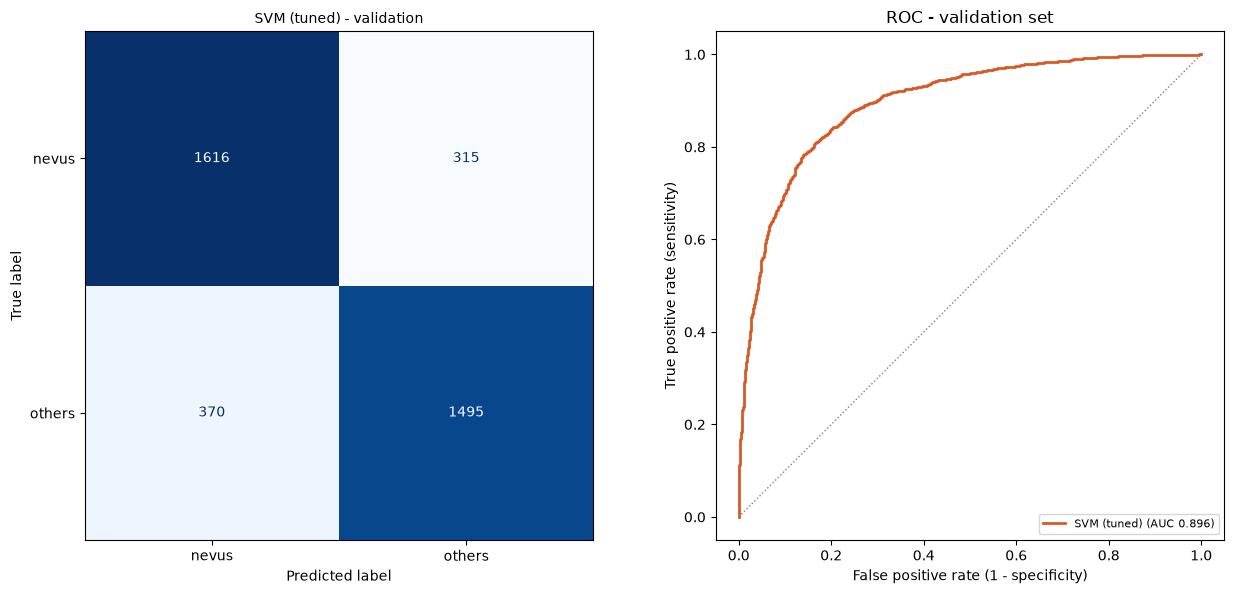

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_confusion(axes[0], y_val, y_pred, "SVM (tuned) - validation")
plot_roc(axes[1], y_val, scores, "SVM (tuned)", MODEL_COLORS["SVM (RBF)"])
finish_roc(axes[1], "ROC - validation set")
plt.tight_layout()
plt.show()

#### Conclusions
The performance on validation is a few points below the cross-validation estimate. This is expected: the hyperparameters were chosen as the best of the CV search, which makes the CV score slightly optimistic. The validation result is the one to report as the final performance of the binary classifier.